## CNN Intuition and Feature Maps

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

### Create a simple image

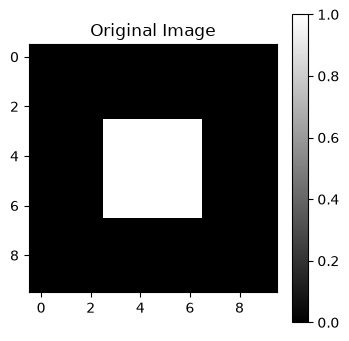

In [2]:
image = np.zeros((10, 10), dtype=np.float32)
image[3:7, 3:7] = 1.0

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray", vmin=0, vmax=1)
plt.title("Original Image")
plt.colorbar()
plt.show()

### Define convolution filters

In [3]:
# Detect vertical edges
vertical_filter = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

# Detect horizontal edges
horizontal_filter = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
], dtype=np.float32)

# Detect general changes in intensity
edge_filter = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

### Apply convolution using TensorFlow

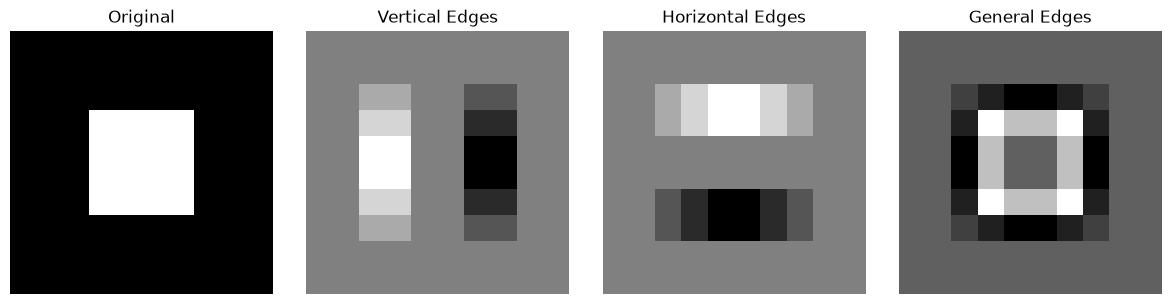

In [4]:
image_tensor = tf.constant(image[None, :, :, None])

filters = {
    "Vertical Edges": vertical_filter,
    "Horizontal Edges": horizontal_filter,
    "General Edges": edge_filter
}

fig, axes = plt.subplots(1, 4, figsize=(12, 3))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original")

for ax, (name, kernel) in zip(axes[1:], filters.items()):
    kernel_tensor = tf.constant(
        kernel[:, :, None, None]
    )

    feature_map = tf.nn.conv2d(
        image_tensor,
        kernel_tensor,
        strides=1,
        padding="SAME"
    )

    ax.imshow(feature_map.numpy()[0, :, :, 0], cmap="gray")
    ax.set_title(name)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
print("Original image shape:", image.shape)
print("Filter shape:", vertical_filter.shape)

feature_map = tf.nn.conv2d(
    image_tensor,
    tf.constant(vertical_filter[:, :, None, None]),
    strides=1,
    padding="SAME"
)

print("Feature map shape:", feature_map.shape)

Original image shape: (10, 10)
Filter shape: (3, 3)
Feature map shape: (1, 10, 10, 1)


### Add a ReLU activation

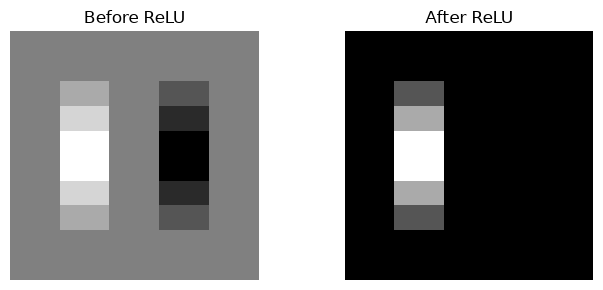

In [6]:
feature_map_relu = tf.nn.relu(feature_map)

fig, axes = plt.subplots(1, 2, figsize=(7, 3))

axes[0].imshow(feature_map.numpy()[0, :, :, 0], cmap="gray")
axes[0].set_title("Before ReLU")

axes[1].imshow(feature_map_relu.numpy()[0, :, :, 0], cmap="gray")
axes[1].set_title("After ReLU")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()